# 1. Set Up - Load Cleaned Dataset
Load the combined datasets of all years (2011 - 2026) with the same settings the modeling notebook uses, so only truly empty cells count as missing (real answers like "None" or "NA" are kept). 

Print the number of respondents per survey year, since sample sizes vary a lot.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
import os; os.makedirs("figures", exist_ok=True)

df = pd.read_csv("combined/all_years_fixed.csv", keep_default_na=False, na_values=[""], low_memory=False)
print(df["survey_year"].value_counts().sort_index())   # rows per year

survey_year
2011     2031
2012     3466
2013     5038
2014     4380
2015    13492
2016    36663
2017    12573
2018    41561
2019    50402
2020    33996
2021    44439
2022    36345
2023    47226
2024    21313
2025    21619
2026    12157
Name: count, dtype: int64


# 2. Missingness Heatmap
In the following heatmap, the darker cells mean a larger share of respondents left the question blank. Fully dark red cells (100%) are years the question wasn't asked, and partial shading reflects respondents skipping a question that was asked. 

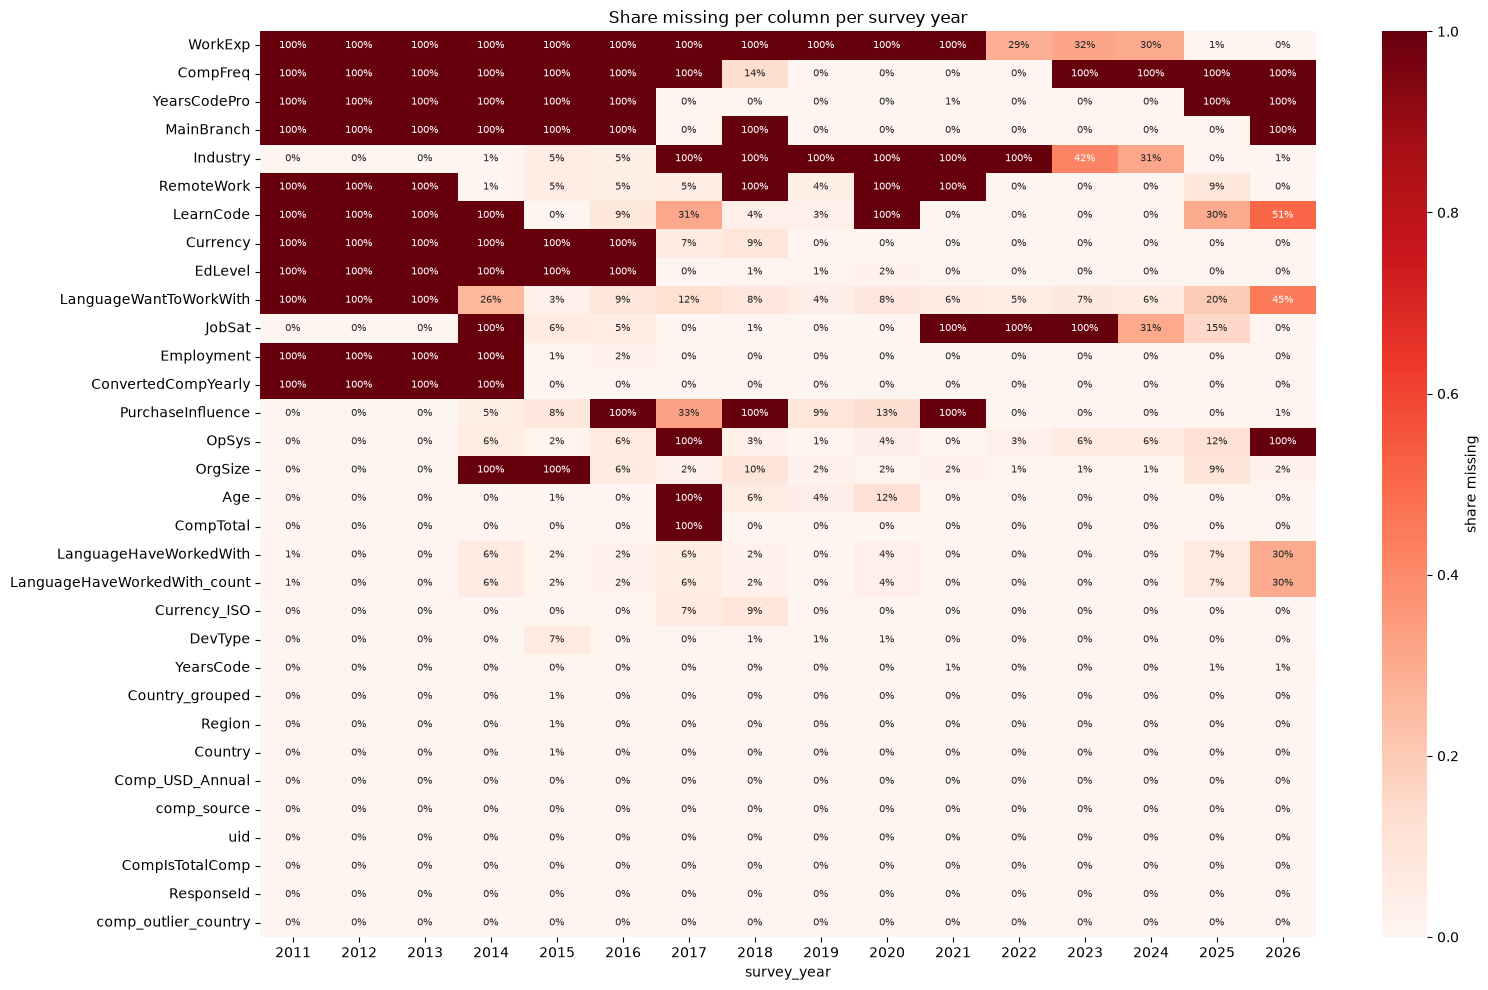

In [2]:
miss = (df.drop(columns="survey_year").isna()
          .groupby(df["survey_year"]).mean().T)
miss = miss.loc[miss.mean(axis=1).sort_values(ascending=False).index]  # worst columns on top
plt.figure(figsize=(16, 10))
sns.heatmap(miss, cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".0%", annot_kws={"size": 7},
            cbar_kws={"label": "share missing"})
plt.title("Share missing per column per survey year"); plt.tight_layout()
plt.savefig("figures/missingness_heatmap.png", dpi=150, bbox_inches="tight")

# 3. Salary Plots (across Survey Years)
**Left:** Median annual salary (USD) per year, on a log scale. Dashed lines mark changes in how the survey collected salary (band midpoints before 2017; base salary before 2019, total compensation after).

**Middle:** Distribution of annual salary per year (USD, log scale). Boxes show the middle 50% of respondents, and whiskers show the typical range.

**Right:** Histogram of annual salary across all years (USD, log scale), used to check whether the log transform makes salaries roughly bell-shaped.

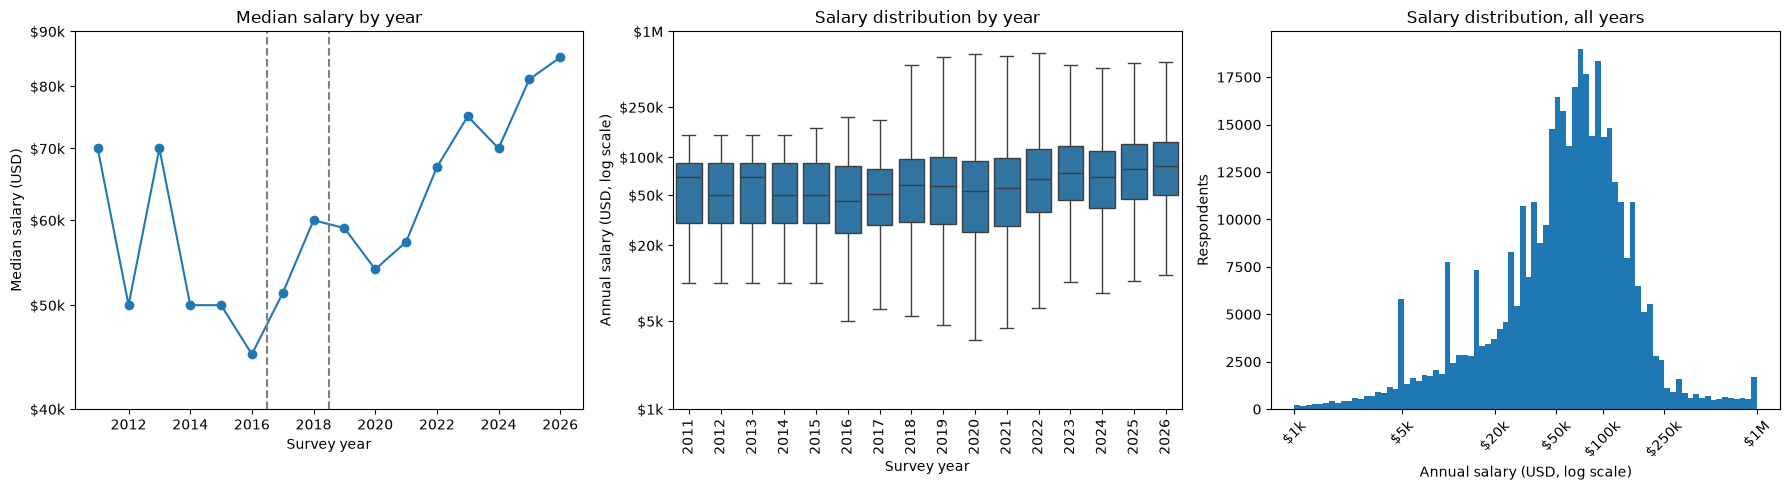

In [3]:
from matplotlib.ticker import FuncFormatter, NullFormatter

def usd(x, pos=None):
    return f"${x/1e6:g}M" if x >= 1e6 else f"${x/1e3:g}k"

log_ticks = [1_000, 5_000, 20_000, 50_000, 100_000, 250_000, 1_000_000]
log_y = np.log(df["Comp_USD_Annual"])

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Left: median by year (dollars on a log axis)
df.groupby("survey_year")["Comp_USD_Annual"].median().plot(marker="o", ax=ax[0], logy=True)
for x in [2016.5, 2018.5]: ax[0].axvline(x, ls="--", c="gray")
ax[0].set_yticks([40_000, 50_000, 60_000, 70_000, 80_000, 90_000])
ax[0].yaxis.set_major_formatter(FuncFormatter(usd))
ax[0].yaxis.set_minor_formatter(NullFormatter())
ax[0].set(title="Median salary by year", xlabel="Survey year", ylabel="Median salary (USD)")

# Middle: salary distribution per year
sns.boxplot(x=df["survey_year"], y=log_y, ax=ax[1], showfliers=False)
ax[1].set_yticks(np.log(log_ticks)); ax[1].set_yticklabels([usd(v) for v in log_ticks])
ax[1].tick_params(axis="x", rotation=90)
ax[1].set(title="Salary distribution by year", xlabel="Survey year", ylabel="Annual salary (USD, log scale)")

# Right: histogram of all salaries
ax[2].hist(log_y, bins=80)
ax[2].set_xticks(np.log(log_ticks)); ax[2].set_xticklabels([usd(v) for v in log_ticks], rotation=45)
ax[2].set(title="Salary distribution, all years", xlabel="Annual salary (USD, log scale)", ylabel="Respondents")

plt.tight_layout()
plt.savefig("figures/salary_by_year.png", dpi=150, bbox_inches="tight")

# 4a. Salary Plots (by Country Group) - Top 15 Countries
Median annual salary (USD) for the 15 country groups with the most respondents, which cover 72% of the data. `Country_grouped` has 128 values: countries with 50 or more respondents keep their name, and smaller ones are pooled into "<Region>, other." That's too many to plot readably, and a median from about 50 people is unreliable next to one from 95,000, so only the largest groups are shown.

Top 15 country groups cover 72% of respondents
Country_grouped
India              11900.0
Brazil             24200.0
Russia             25000.0
Ukraine            30000.0
Poland             38100.0
Italy              38700.0
Spain              43000.0
France             51200.0
Sweden             58300.0
Netherlands        64000.0
Germany            68200.0
United Kingdom     70000.0
Canada             74400.0
Australia          85300.0
United States     115000.0
Name: Comp_USD_Annual, dtype: float64


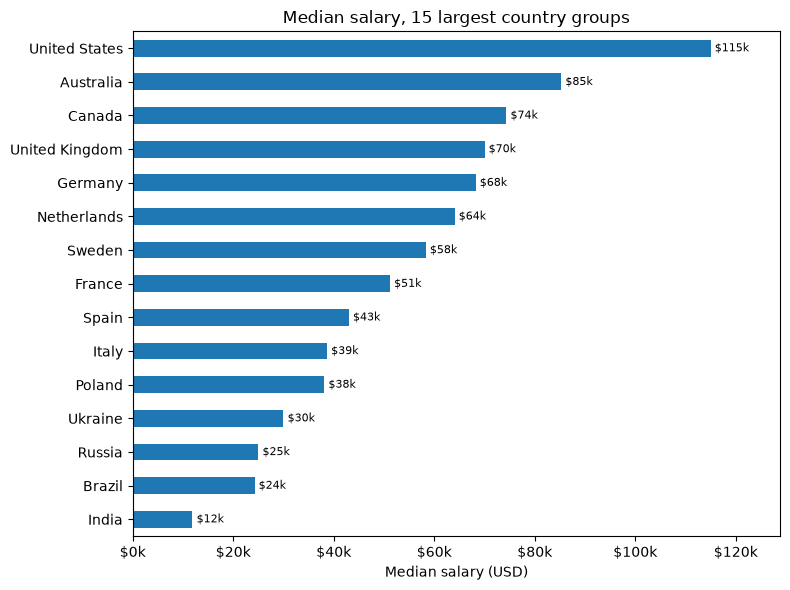

In [4]:
counts = df["Country_grouped"].value_counts()
top = counts.head(15).index
print(f"Top 15 country groups cover {counts.head(15).sum() / counts.sum():.0%} of respondents")

med = df[df["Country_grouped"].isin(top)].groupby("Country_grouped")["Comp_USD_Annual"].median().sort_values()
ax = med.plot.barh(figsize=(8, 6))
ax.xaxis.set_major_formatter(FuncFormatter(usd))
ax.bar_label(ax.containers[0], labels=[f"${v/1e3:.0f}k" for v in med], padding=3, fontsize=8)
ax.set_xlim(0, med.max() * 1.12)
ax.set(title="Median salary, 15 largest country groups", xlabel="Median salary (USD)", ylabel="")
plt.tight_layout()
plt.savefig("figures/salary_top15_countries.png", dpi=150, bbox_inches="tight")
print(med.round(-2))

# 4b. Salary Plots (by Country Group) - 9 Regions
Median annual salary (USD) for each of the 9 world regions. The top 15 countries leave out the remaining 113 groups, which are mostly smaller and lower-paid countries. To summarize everyone, this uses the `Region` column created in the cleaning notebook. Region is for EDA only; the model uses `Country_grouped`. Note: the "Other" region has only 187 respondents, so its median is less reliable.

Region
Asia                            14900.0
Africa                          18200.0
Central America & Caribbean     24500.0
South America                   24900.0
Europe                          55000.0
Other                           55000.0
Middle East                     55500.0
Oceania                         81300.0
North America                  108000.0
Name: Comp_USD_Annual, dtype: float64


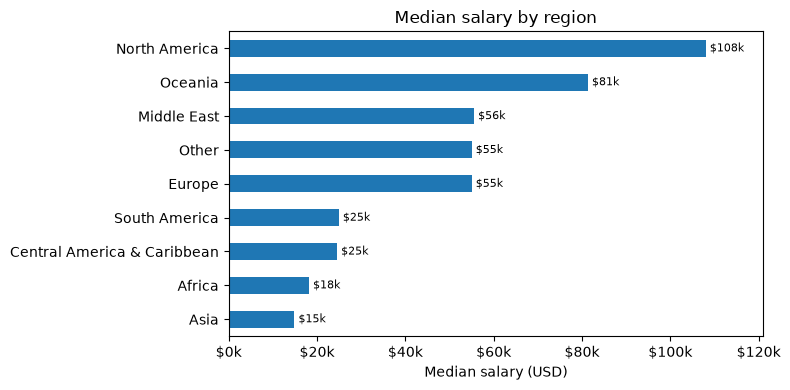

In [5]:
med_r = df.groupby("Region")["Comp_USD_Annual"].median().sort_values()
ax = med_r.plot.barh(figsize=(8, 4))
ax.xaxis.set_major_formatter(FuncFormatter(usd))
ax.bar_label(ax.containers[0], labels=[f"${v/1e3:.0f}k" for v in med_r], padding=3, fontsize=8)
ax.set_xlim(0, med_r.max() * 1.12)
ax.set(title="Median salary by region", xlabel="Median salary (USD)", ylabel="")
plt.tight_layout()
plt.savefig("figures/salary_by_region.png", dpi=150, bbox_inches="tight")
print(med_r.round(-2))

# 5. Analysis

**Missingness Percentage Heatmap:** Most missing values are structural: whole survey years left certain questions out, and every fully blank year-column combination matches the "Not asked" rules used in preprocessing. Skipping is otherwise low, except in 2026, our test year, where LearnCode (51%), LanguageWantToWorkWith (45%), and LanguageHaveWorkedWith (30%) are often blank, so the test year differs from the training data.

**Salary Plots Per Year:** Median salary rises from about 54k USD in 2020 to 85k USD in 2026 (wage growth, inflation and the 2019 switch to total compensation), so a model trained on earlier years will likely underpredict 2026. Before 2017, salaries were recorded as bands, which explains the zigzagging medians and histogram spikes; on a log scale, salaries are roughly bell-shaped, supporting the log transform of the target.

**Salary Plots Per Country - Top 15 Countries & 9 Regions:** Location is the largest source of salary variation: medians range from 11.9k USD in India to 115k USD in the United States, a far bigger gap than across survey years. Region medians mostly reflect each region's biggest country (e.g., India in Asia), which supports using Country_grouped (128 values) rather than Region in the model.